# ESS DD cavity pulses: what we asked and what came out

`ess_dd/` holds the DD captures of all 81 cavities, `ess_pm/` the PM captures taken at each trip and their beam
position waveforms,
`ess_dd_one_cavity/` the run on `MBL-090RFC:RFS-DIG-101` with beam, `ess_archiver/` the slow RF signals around the
trips. Code is in the notebook or script of each folder.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

INK, MUTED, SURFACE, GRID, GREY, CRITICAL = "#1a1a19", "#6b6b66", "#fcfcfb", "#e6e5e0", "#b9b8b0", "#d03b3b"
COLOR = {"field amplitude": "#2a78d6", "field phase": "#eb6834", "forward": "#1baf7a", "reflected": "#eda100"}
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": GRID, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 100, "display.max_colwidth", 80)

pulses = pd.read_parquet("ess_dd/cavity_pulses.parquet")
context = pd.read_parquet("ess_dd/context_correlation.parquet")
comovement = pd.read_parquet("ess_dd/cavity_comovement.parquet")
one = pd.read_parquet("ess_dd_one_cavity/one_cavity_pulses.parquet")
# The trip timings of the one cavity come from the table of all cavities.
one = one.merge(pulses[["event_id", "cycle_id", "cavity", "seconds_to_next_trip"]], on=["event_id", "cycle_id", "cavity"], validate="one_to_one")
# Cut: flat top shorter than 90 % of the median of the cavity. Before a trip: the beam permit drops within a second.
one["is_cut"] = one.flat_len < 0.9 * one.flat_len.median()
one["before_trip"] = one.seconds_to_next_trip < 1

pd.DataFrame({"pulses": [len(pulses), len(one)], "cavities": [pulses.cavity.nunique(), one.cavity.nunique()],
              "captures": [pulses.event_id.nunique(), one.event_id.nunique()], "beam": ["with and without", "present only"]},
             index=["all cavities", "MBL-090RFC:RFS-DIG-101"])

,pulses,cavities,captures,beam
all cavities,35414,81,43,with and without
MBL-090RFC:RFS-DIG-101,311,1,24,present only


## 1. What are the features and where do they come from?

None is a raw column. Every feature is computed from one of four raw waveforms of the cavity.

In [2]:
# The raw waveform each feature is computed from, and what the feature measures.
FEATURES = {
    "shape_drift": ("field amplitude", "whole pulse shape against the earlier pulses of the capture"),
    "flat_len": ("field amplitude", "length of the flat top"),
    "flat_len_drift": ("field amplitude", "flat-top length against the earlier pulses"),
    "pulse_len": ("field amplitude", "length above half of the level"),
    "flat_std_rel_drift": ("field amplitude", "flat-top ripple against the earlier pulses"),
    "flat_std_rel": ("field amplitude", "ripple on the flat top"),
    "flat_step_max_rel": ("field amplitude", "largest sudden step on the flat top"),
    "flat_p2p_rel": ("field amplitude", "peak to peak on the flat top"),
    "flat_max_dev_rel": ("field amplitude", "largest single deviation on the flat top"),
    "flat_tilt_rel": ("field amplitude", "slope of the flat top"),
    "flat_tilt_rel_drift": ("field amplitude", "flat-top slope against the earlier pulses"),
    "field_level": ("field amplitude", "height of the field"),
    "field_level_drift": ("field amplitude", "field height against the earlier pulses"),
    "rise_len": ("field amplitude", "time to rise from 10 to 90 %"),
    "fall_len": ("field amplitude", "time to fall from 90 to 10 %"),
    "decay_tau": ("field amplitude", "time constant of the fall"),
    "decay_tau_drift": ("field amplitude", "time constant of the fall against the earlier pulses"),
    "field_end_after_rf_off": ("field amplitude", "end of the flat top relative to the forward power going off"),
    "phase_mean_deg": ("field phase", "mean phase on the flat top"),
    "phase_mean_deg_drift": ("field phase", "mean phase against the earlier pulses"),
    "phase_std_deg": ("field phase", "phase jitter on the flat top"),
    "phase_p2p_deg": ("field phase", "phase peak to peak on the flat top"),
    "phase_tilt_deg": ("field phase", "phase slope across the flat top"),
    "fwd_flat": ("forward", "forward power on the flat top"),
    "fwd_flat_drift": ("forward", "forward power against the earlier pulses"),
    "fwd_flat_std_rel": ("forward", "ripple of the forward power on the flat top"),
    "fwd_peak": ("forward", "peak of the forward power while the cavity fills"),
    "refl_flat": ("reflected", "reflected power on the flat top"),
    "refl_fill_peak": ("reflected", "reflected peak while the cavity fills"),
    "refl_end_peak": ("reflected", "reflected peak when the cavity empties"),
    "refl_ratio": ("reflected", "reflected over forward on the flat top"),
    "refl_ratio_drift": ("reflected", "reflected over forward against the earlier pulses"),
}
SOURCES = {"field amplitude": "Dwn0-Cmp0: strength of the accelerating field through the pulse",
           "field phase": "Dwn0-Cmp1: timing of the field against the machine reference",
           "forward": "Dwn5-Cmp0: power sent into the cavity",
           "reflected": "Dwn6-Cmp0: power coming back out of the cavity"}


pd.Series(SOURCES, name="raw waveform").to_frame()

,raw waveform
field amplitude,Dwn0-Cmp0: strength of the accelerating field through the pulse
field phase,Dwn0-Cmp1: timing of the field against the machine reference
forward,Dwn5-Cmp0: power sent into the cavity
reflected,Dwn6-Cmp0: power coming back out of the cavity


## 2. What moves with what?

All cavities. The strongest links between a feature and the beam, the trips or the place in the capture.
Spearman uses the order of the values, Pearson the values: they differ where a column is lopsided, as beam
current (most captures near 4,400, a few at 62,000) and the time since the last trip (seconds to days).

In [3]:
top = context[context.section == "all"].assign(strength=lambda d: d.spearman_r.abs()).sort_values("strength", ascending=False)
top.head(6)[["feature", "context", "spearman_r", "pearson_r"]].round(2).reset_index(drop=True)

,feature,context,spearman_r,pearson_r
0,fwd_flat_std_rel,beam_level,0.83,0.96
1,fwd_flat_std_rel,beam_current,0.80,0.95
2,flat_step_max_rel,beam_current,0.69,0.52
3,flat_step_max_rel,beam_level,0.62,0.62
4,fwd_flat_std_rel,beam_after_flat_start_us,-0.49,-0.39
5,refl_ratio,seconds_since_last_trip,-0.49,-0.09


## 3. Do cavities move together?

All cavities, pulse to pulse within a capture. Only the flat-top phase does, and it fades over the next cycles.

In [4]:
(comovement.groupby(["feature", "lag_cycles", "same_section"]).spearman_r.mean().round(2)
 .unstack(["lag_cycles", "same_section"]).rename_axis(columns=["cycles later", "same section"]))

cycles later       0           1           2      
same section   False True  False True  False True 
feature                                           
field_level     0.01  0.02  0.01  0.01  0.00  0.01
flat_len        0.02  0.04  0.02  0.03  0.02  0.03
flat_std_rel    0.03  0.05  0.01  0.03  0.01  0.02
phase_mean_deg  0.19  0.38  0.14  0.27  0.09  0.17
refl_ratio      0.00  0.00 -0.00 -0.00  0.00 -0.00

## 4. Is there an anomaly in the data, and what is it?

Two cycles have many cavities with a flat top far shorter than in the other cycles of their capture, both about
0.6 s before a beam trip. On `MBL-090RFC:RFS-DIG-101` one of them is in the data with beam: the forward power goes
off early in the flat top and the field drains from there. That is the RF cut.

In [5]:
live = pulses[pulses.has_pulse]
short = live[live.flat_len < 0.9 * live.groupby(["event_id", "cavity"]).flat_len.transform("median")]
(short.groupby(["event_id", "cycle_id"])
 .agg(cavities=("cavity", "size"), sections=("section", lambda s: " ".join(sorted(set(s)))), flat_len=("flat_len", "median"),
      seconds_to_next_trip=("seconds_to_next_trip", "first"), beam_state=("beam_state", "first"))
 .query("cavities > 1").sort_values("cavities", ascending=False))

,,cavities,sections,flat_len,seconds_to_next_trip,beam_state
event_id,cycle_id,,,,,
16122602164,16122596526,43,HBL MBL,1855.0,0.632005,BEAM_PRESENT_YES
16122702964,16122697297,9,HBL MBL,1814.0,0.610176,BEAM_PRESENT_YES_FAKE


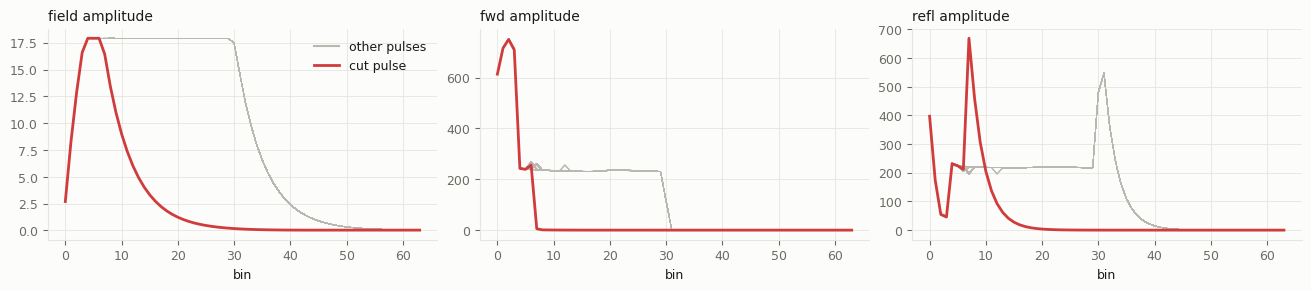

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8), constrained_layout=True)
for ax, name in zip(axes, ["field_amp_bins", "fwd_amp_bins", "refl_amp_bins"]):
    ax.plot(np.stack(one.loc[~one.is_cut, name]).T, color=GREY, linewidth=0.5, alpha=0.5)
    ax.plot(np.stack(one.loc[one.is_cut, name]).T, color=CRITICAL, linewidth=2)
    ax.set_title(name.replace("_bins", "").replace("amp", "amplitude").replace("_", " "), loc="left", fontsize=10)
    ax.set_xlabel("bin")
    ax.grid(color=GRID, linewidth=0.6)
axes[0].plot([], [], color=GREY, label="other pulses")
axes[0].plot([], [], color=CRITICAL, linewidth=2, label="cut pulse")
axes[0].legend(frameon=False)
plt.show()

## 5. Which features find it?

`MBL-090RFC:RFS-DIG-101` only, 311 pulses with beam, one cut pulse.

- **distance**: how far the cut pulse sits from the median of the cavity, in units of the usual spread;
- **normal 99 % line**: the distance that 99 % of the pulses not before a trip stay under;
- **times over**: distance divided by that line. Above 1 the feature finds the cut pulse; the larger, the clearer.

In [7]:
def robust_z(s):
    spread = 1.4826 * (s - s.median()).abs().median()
    return (s - s.median()) / (spread if spread > 0 else s.std())


z = one[list(FEATURES)].apply(robust_z).abs()
table = pd.DataFrame({"distance": z[one.is_cut].max(), "normal_99_line": z[~one.before_trip].quantile(0.99)})
table["times_over"] = table.distance / table.normal_99_line
table["importance"] = pd.cut(table.times_over, [0, 1, 5, 10, 100, np.inf], labels=["none", "low", "medium", "high", "very high"]).astype(str)
# A normal line above 10 means the feature already swings widely on normal pulses, here with the beam setting.
table["helps_find_the_cut"] = np.select([table.times_over <= 1, table.times_over <= 5, table.normal_99_line > 10], ["no", "weak", "yes, noisy normal"], "yes")
table["computed_from"] = [FEATURES[f][0] for f in table.index]
table["measures"] = [FEATURES[f][1] for f in table.index]
table = table.sort_values("times_over", ascending=False)
table.round({"distance": 1, "normal_99_line": 1, "times_over": 1})

,distance,normal_99_line,times_over,importance,helps_find_the_cut,computed_from,measures
shape_drift,15009.0,2.7,5511.3,very high,yes,field amplitude,whole pulse shape against the earlier pulses of the capture
flat_len_drift,8699.6,2.7,3224.5,very high,yes,field amplitude,flat-top length against the earlier pulses
flat_len,8699.6,2.7,3224.5,very high,yes,field amplitude,length of the flat top
pulse_len,8694.9,2.7,3222.8,very high,yes,field amplitude,length above half of the level
flat_std_rel_drift,822.0,3.0,277.4,very high,yes,field amplitude,flat-top ripple against the earlier pulses
phase_std_deg,126.5,3.0,42.0,high,yes,field phase,phase jitter on the flat top
phase_tilt_deg,98.1,2.4,40.5,high,yes,field phase,phase slope across the flat top
flat_tilt_rel_drift,90.0,2.7,32.9,high,yes,field amplitude,flat-top slope against the earlier pulses
flat_step_max_rel,290.2,11.8,24.7,high,"yes, noisy normal",field amplitude,largest sudden step on the flat top
flat_std_rel,383.7,21.5,17.8,high,"yes, noisy normal",field amplitude,ripple on the flat top


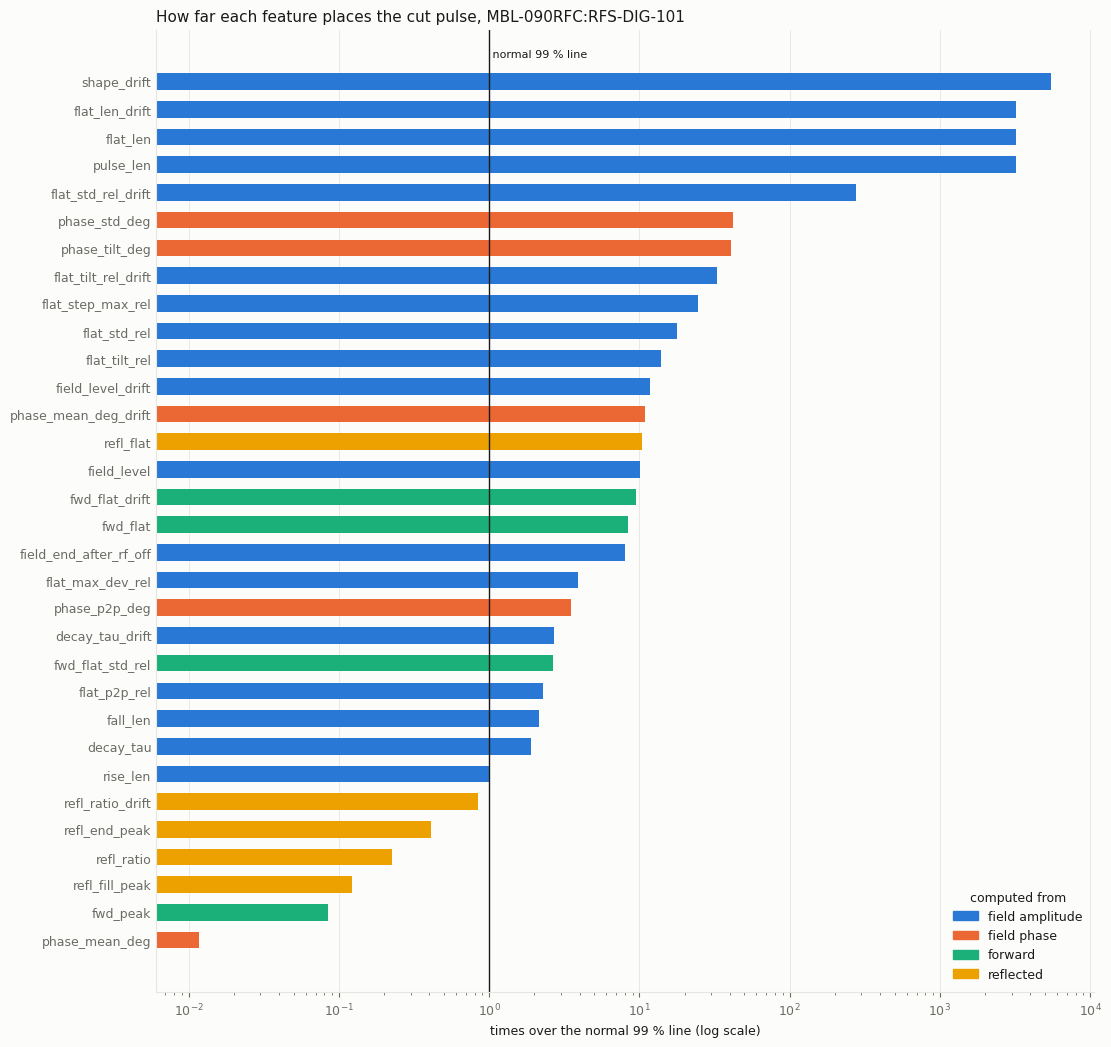

In [8]:
shown = table.iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 0.28 * len(shown) + 1.4), constrained_layout=True)
ax.barh(range(len(shown)), shown.times_over.clip(lower=0.01), height=0.6, color=[COLOR[s] for s in shown.computed_from])
ax.axvline(1, color=INK, linewidth=1)
ax.text(1, len(shown) - 0.2, " normal 99 % line", color=INK, fontsize=8, va="bottom")
ax.set_xscale("log")
ax.set_yticks(range(len(shown)), shown.index)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
ax.set_xlabel("times over the normal 99 % line (log scale)")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLOR.values()], COLOR.keys(), title="computed from", frameon=False, loc="lower right")
ax.set_title("How far each feature places the cut pulse, MBL-090RFC:RFS-DIG-101", loc="left", fontsize=11)
plt.show()

## 6. Where do the trips come from?

The interlock log names the system that drops with each of the 101 trips. It names a system, not a cavity.

In [9]:
mps = pd.read_parquet("ess_dd/mps_transitions.parquet")
PERMIT = "FBIS::beam_permit_ok"
trips = mps[(mps.pv == PERMIT) & (mps.value == 0)].data_ts.reset_index(drop=True)
drops = mps[(mps.pv != PERMIT) & (mps.value == 0)]


def trip_kind(t):
    """Which interlocks drop within a few seconds of the beam permit."""
    near = drops[(drops.data_ts >= t - pd.Timedelta("5s")) & (drops.data_ts <= t + pd.Timedelta("3s"))]
    systems = {pv.split("::")[-1].replace("-FBIS_ok", "") for pv in near.pv}
    if not systems:
        return "nothing else logged"
    if systems == {"RFLPS"}:
        return "RF protection"
    return "RF protection and beam" if "RFLPS" in systems else "beam instruments"


trips.map(trip_kind).value_counts().rename("trips").to_frame()

,trips
data_ts,
RF protection,37
beam instruments,35
nothing else logged,23
RF protection and beam,6


For the cycle with 43 cavities cut, the order of the drops: the beam goes wrong first, the RF is switched off after.

In [10]:
cut_trip = trips[(trips - pd.Timestamp("2026-06-29 18:13:56.69", tz="UTC")).abs().idxmin()]
near = drops[(drops.data_ts - cut_trip).abs() < pd.Timedelta("2s")]
pd.DataFrame({"interlock": near.pv, "ms before the beam permit": ((cut_trip - near.data_ts).dt.total_seconds() * 1e3).round(0)}).reset_index(drop=True)

,interlock,ms before the beam permit
0,MPSoS::BCM-FBIS_ok,38.0
1,MPSoS::BPM-FBIS_ok,26.0
2,MPSoS::RFLPS-FBIS_ok,1.0


## 7. Does anything announce a trip?

No. The PM captures hold the last seconds before 52 trips, one pulse per second, all cavities. Each cavity is
compared with its own pulses earlier in the same capture.

In the RF protection trips, many cavities shift 2 s before the logged trip. The beam monitors read no beam from
that same second: the cavities shift because the beam stopped. The logged trip time runs about 2 s late.

In [11]:
keep = ["event_id", "cycle_id", "cavity", "cycle_rank_from_last", "seconds_to_next_trip", "has_pulse", "beam_level", "flat_len",
        "field_end_after_rf_off", "field_level", "flat_std_rel", "flat_tilt_rel", "phase_mean_deg", "fwd_flat", "refl_flat", "refl_ratio"]
pm = pd.read_parquet("ess_pm/cavity_pulses.parquet", columns=keep)
pm = pm[pm.has_pulse]
last = pm.groupby("event_id").agg(ts=("seconds_to_next_trip", "min"))
pm = pm[pm.event_id.isin(last[last.ts < 1].index)]
# The time of the trip of each capture, to look up its kind in the interlock log.
stamp = pd.read_parquet("ess_pm/cavity_pulses.parquet", columns=["event_id", "cycle_ts", "seconds_to_next_trip"])
stamp = stamp.loc[stamp.groupby("event_id").seconds_to_next_trip.idxmin()]
stamp["kind"] = [trip_kind(trips[(trips - (t + pd.Timedelta(seconds=x))).abs().idxmin()]) for t, x in zip(stamp.cycle_ts, stamp.seconds_to_next_trip)]
pm = pm.merge(stamp[["event_id", "kind"]], on="event_id")

# A pulse is out when one of these is more than 8 of the cavity's own spreads from its level 6 s or more before the end.
OWN = ["field_level", "flat_std_rel", "flat_tilt_rel", "phase_mean_deg", "fwd_flat", "refl_flat", "refl_ratio"]
earlier = pm[pm.cycle_rank_from_last >= 6]
level = earlier.groupby(["event_id", "cavity"])[OWN].median()
spread = 1.4826 * (earlier[OWN] - earlier.groupby(["event_id", "cavity"])[OWN].transform("median")).abs().groupby([earlier.event_id, earlier.cavity]).median()
rows = pd.MultiIndex.from_frame(pm[["event_id", "cavity"]])
pm["out"] = (np.abs(pm[OWN].to_numpy() - level.reindex(rows).to_numpy()) / spread.reindex(rows).replace(0, np.nan).to_numpy() > 8).any(axis=1)
pm["cut"] = pm.flat_len < 0.9 * pm.groupby(["event_id", "cavity"]).flat_len.transform("median")
end = pm[pm.cycle_rank_from_last == 0].groupby(["kind", "event_id"]).agg(cut=("cut", "sum"), out=("out", "mean"))
print(f"pulses where the field leaves the flat top while the forward power is on: {int((pm.field_end_after_rf_off < -200).sum())}")
end.groupby("kind").agg(trips=("cut", "size"), trips_with_a_cut=("cut", lambda x: int((x > 0).sum())),
                        cavities_out_at_the_last_pulse=("out", lambda x: f"{100 * x.median():.0f} %"))

pulses where the field leaves the flat top while the forward power is on: 0


,trips,trips_with_a_cut,cavities_out_at_the_last_pulse
kind,,,
RF protection,27,3,42 %
RF protection and beam,4,0,98 %
beam instruments,18,0,33 %
nothing else logged,3,0,31 %


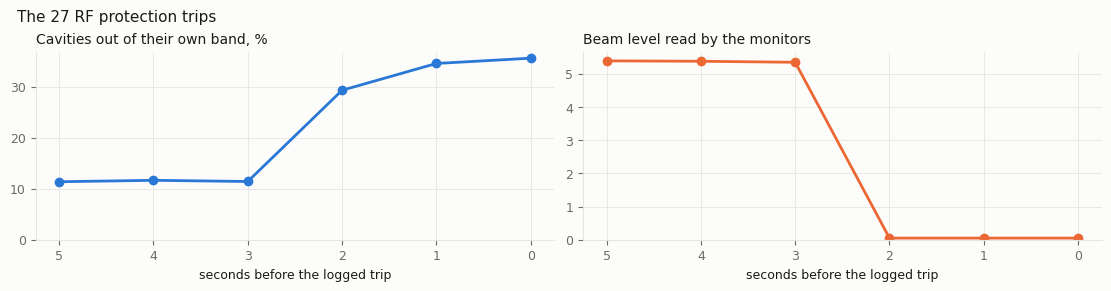

In [12]:
rf = pm[(pm.kind == "RF protection") & (pm.cycle_rank_from_last <= 5)]
by_second = rf.groupby("cycle_rank_from_last").agg(out=("out", "mean"), beam=("beam_level", "median")).sort_index(ascending=False)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 2.8), constrained_layout=True)
left.plot(by_second.index, 100 * by_second.out, color=COLOR["field amplitude"], linewidth=2, marker="o")
left.set_title("Cavities out of their own band, %", loc="left", fontsize=10)
right.plot(by_second.index, by_second.beam, color=COLOR["field phase"], linewidth=2, marker="o")
right.set_title("Beam level read by the monitors", loc="left", fontsize=10)
for ax in (left, right):
    ax.invert_xaxis()
    ax.set_xlabel("seconds before the logged trip")
    ax.set_ylim(bottom=0)
    ax.grid(color=GRID, linewidth=0.6)
fig.suptitle(f"The {rf.event_id.nunique()} RF protection trips", x=0.01, ha="left", fontsize=11)
plt.show()

The same question asked the direct way: PM pulses against nominal DD pulses of the same cavity, the same beam
setting and the same days. A pulse is off when 3 or more features sit outside the band holding 99 % of the
nominal pulses. Before the trip, the PM pulses are no more off than a nominal capture set against the others.
At the last pulse it splits: in some trips nearly every cavity is off, in the others none.

In [13]:
SETTING = ["cavity", "beam_present", "beam_mode", "beam_current"]
SHAPE = [f for f in FEATURES if not f.endswith("_drift")]
columns = ["event_id", "capture_window", "has_pulse", "array_size", "cycle_rank_from_last", "seconds_to_next_trip"] + SETTING + SHAPE
trip_pulses = pd.read_parquet("ess_pm/cavity_pulses.parquet", columns=columns)
days = set(trip_pulses.capture_window) & set(pulses.capture_window)
usable = lambda t: t[t.has_pulse & t.capture_window.isin(days) & (t.array_size == pulses.array_size.max())]
trip_pulses, nominal = usable(trip_pulses), usable(pulses[columns])
nominal = nominal[~(nominal.seconds_to_next_trip < 1)]


def off(test, reference):
    """Whether each test pulse is outside the reference band on 3 or more features; needs 30 reference pulses."""
    band = reference.groupby(SETTING)[SHAPE]
    low, high, count = band.quantile(0.005), band.quantile(0.995), band.size()
    rows = pd.MultiIndex.from_frame(test[SETTING])
    outside = (test[SHAPE].to_numpy() < low.reindex(rows).to_numpy()) | (test[SHAPE].to_numpy() > high.reindex(rows).to_numpy())
    return pd.Series(outside.sum(axis=1) >= 3, index=test.index)[count.reindex(rows).fillna(0).to_numpy() >= 30]


held_out = pd.concat([off(x, nominal[nominal.event_id != e]) for e, x in nominal.groupby("event_id")])
against = off(trip_pulses, nominal)
rank = trip_pulses.cycle_rank_from_last.reindex(against.index)
def row(flags, of):
    per_capture = flags.groupby(of.event_id.reindex(flags.index)).mean()
    return {"captures": len(per_capture), "pulses off, %": round(100 * flags.mean(), 1), "captures with most cavities off": int((per_capture > 0.5).sum())}


pd.DataFrame({"nominal captures, each against the others": row(held_out, nominal),
              "PM, 6 s or more before the trip": row(against[rank >= 6], trip_pulses),
              "PM, last pulse": row(against[rank == 0], trip_pulses)}).T

,captures,"pulses off, %",captures with most cavities off
"nominal captures, each against the others",26.0,21.6,3.0
"PM, 6 s or more before the trip",14.0,12.9,0.0
"PM, last pulse",12.0,70.8,8.0


The beam current monitors, same idea: each monitor against its own earlier pulses, counted back from the last
pulse that still has beam. The beam looks normal until that last pulse.

In [14]:
beam = pd.read_parquet("ess_pm/beam_pulses.parquet")
beam = beam[beam.event_id.isin(pm.event_id.unique())]
cycles = beam.groupby(["event_id", "cycle_id"]).agg(monitors=("device", "size"), with_beam=("has_beam", "sum")).reset_index().sort_values(["event_id", "cycle_id"])
cycles["from_end"] = cycles.groupby("event_id").cumcount(ascending=False)
last_beam = cycles[cycles.with_beam >= cycles.monitors / 2].groupby("event_id").from_end.min().rename("last_beam")
cycles = cycles.merge(last_beam, on="event_id")
cycles["before_last_beam"] = cycles.from_end - cycles.last_beam
beam = beam[beam.has_beam].merge(cycles[["event_id", "cycle_id", "before_last_beam"]], on=["event_id", "cycle_id"]).query("before_last_beam >= 0")
BEAM = ["beam_level", "beam_len_us", "beam_start_us", "beam_flat_std_rel", "beam_charge"]
earlier = beam[beam.before_last_beam >= 6]
level = earlier.groupby(["event_id", "device"])[BEAM].median()
spread = 1.4826 * (earlier[BEAM] - earlier.groupby(["event_id", "device"])[BEAM].transform("median")).abs().groupby([earlier.event_id, earlier.device]).median()
rows = pd.MultiIndex.from_frame(beam[["event_id", "device"]])
beam["out"] = (np.abs(beam[BEAM].to_numpy() - level.reindex(rows).to_numpy()) / spread.reindex(rows).replace(0, np.nan).to_numpy() > 8).any(axis=1)
beam = beam[earlier.groupby(["event_id", "device"]).size().reindex(rows).fillna(0).to_numpy() >= 5]
(beam[beam.before_last_beam <= 5].groupby("before_last_beam").agg(trips=("event_id", "nunique"), readings_out=("out", lambda x: f"{100 * x.mean():.1f} %"))
 .sort_index(ascending=False).rename_axis("pulses before the last pulse with beam"))

,trips,readings_out
pulses before the last pulse with beam,,
5,44,3.1 %
4,44,1.5 %
3,44,1.5 %
2,44,5.6 %
1,44,5.6 %
0,44,14.9 %


## 8. Can a model tell a trip from normal?

A random forest on the same features, scored on captures it has not seen (0.5 = chance). It tells trip captures
from nominal ones 3 to 5 s before the trip, but only through the beam setting: trips happen at beam currents the
nominal captures never ran at. With the same beam current on both sides, it is at chance.

In [15]:
forest = pd.read_parquet("ess_pm/random_forest.parquet")
forest.groupby("question", sort=False).auc.first().round(2).rename("ROC-AUC").to_frame()

,ROC-AUC
question,
trip pulse,0.75
before trip,0.62
"before trip, same beam current",0.47
beam current alone,0.73
control,0.47


## 9. Is a network better than the features?

Not here. A convolutional autoencoder on the 311 pulses of `MBL-090RFC:RFS-DIG-101`, scored on captures it has
not seen, finds the cut pulse as well as `shape_drift`, with a wider normal range, and its error follows the
beam current. It is what the challenge scores.

In [16]:
ae = pd.read_parquet("ess_dd_one_cavity/ae_errors.parquet").merge(one, on=["event_id", "cycle_id", "cavity"])
pd.DataFrame({name: {"rank of the cut pulse": int(ae[c].rank(ascending=False)[ae.is_cut].iloc[0]),
                     "cut pulse over the worst normal pulse": round(float(ae[c][ae.is_cut].iloc[0] / ae[c][~ae.is_cut].max())),
                     "worst normal pulse over the median": round(float(ae[c][~ae.is_cut].max() / ae[c][~ae.is_cut].median()), 1),
                     "rank correlation with beam current": round(float(ae[c][~ae.is_cut].rank().corr(ae.beam_current[~ae.is_cut].rank())), 2)}
              for name, c in [("autoencoder error", "recon_mse"), ("shape_drift", "shape_drift")]})

,autoencoder error,shape_drift
rank of the cut pulse,1.00,1.00
cut pulse over the worst normal pulse,1138.00,2065.00
worst normal pulse over the median,22.10,6.00
rank correlation with beam current,0.16,-0.05


## 10. Does any slow signal of the Archiver announce a trip?

No. The Archiver gives 2,246 signals: the voltage of the modulators, the current of their klystrons, the RF levels,
tuning and temperatures of the RFQ, the DTL and the bunchers, the 85 beam position monitors at each beam pulse, the
magnet power supplies, the vacuum gauges, the cryogenics, and the share of the beam that reaches each beam current
monitor. Each signal is compared with its own level 2 minutes to
20 s earlier, around 47 trips, counted from the last beam pulse. A trip is flagged when more signals moved than in
99 % of the quiet moments of the same run and beam current.

Nothing moves before the beam stops. The modulators, klystrons, magnets, vacuum and cryogenics do not move after it
either. The front end RF levels shift once the beam is gone. Of the 3 trips the beam position monitors flag in the
last 5 s, 2 have a last pulse that already lost beam, with the pulse before it normal, and 1 is just past the limit.
The one trip the magnets flag (2025-05-30 00:50:45 UTC) has the DC link voltage of 75 power supplies off in the last
5 s and 95 after.

In [17]:
archiver = pd.read_parquet("ess_archiver/pretrip_summary.parquet")
SPANS = ["20 to 5 s before", "last 5 s", "second of the trip", "1 to 3 s after"]
ROWS = ["modulator voltage", "klystron current", "modulator oil", "front end RF level", "front end cavity tuning",
        "front end temperature", "all RF signals", "beam position", "beam phase", "beam signal strength",
        "all beam position monitor signals", "magnet power supply", "vacuum pressure", "cryomodule", "cryo plant",
        "superconducting RF temperature", "all magnet, vacuum and cryo signals", "beam transmission", "beam current"]
at_trips = archiver[archiver.kind != "quiet moment"].groupby(["group", "span"])[["flagged", "events"]].sum()
table = (at_trips.flagged.astype(str) + " of " + at_trips.events.astype(str)).unstack()[SPANS]
table.insert(0, "signals", archiver.groupby("group").signals.first())
table.loc[ROWS].rename_axis(index="trips flagged", columns=None)

,signals,20 to 5 s before,last 5 s,second of the trip,1 to 3 s after
trips flagged,,,,,
modulator voltage,16,0 of 47,0 of 47,0 of 47,0 of 47
klystron current,62,0 of 47,0 of 47,1 of 47,0 of 47
modulator oil,32,0 of 47,0 of 47,0 of 47,0 of 47
front end RF level,49,2 of 47,1 of 47,3 of 47,27 of 47
front end cavity tuning,18,1 of 47,2 of 47,2 of 47,1 of 47
front end temperature,15,1 of 47,1 of 47,0 of 47,1 of 47
all RF signals,192,0 of 47,0 of 47,2 of 47,23 of 47
beam position,170,1 of 47,2 of 47,24 of 47,24 of 47
beam phase,85,2 of 47,2 of 47,24 of 47,24 of 47


By kind of trip. The quiet moments are what chance gives: about 1 %. What the signals see at a trip follows the
year, not the kind of trip: the beam position monitors are flagged in the second of the trip in 18 of 18 trips of
2025 and 6 of 29 of 2026, the front end RF levels after it in 1 of 18 and 26 of 29. Of the 20 RF protection trips 17
are from 2025, so these signals cannot be used to tell an RF trip from a beam trip.

In [18]:
every = archiver[archiver.group.str.startswith("all ")]
(every.flagged.astype(str) + " of " + every.events.astype(str)).set_axis(pd.MultiIndex.from_frame(every[["group", "kind", "span"]])).unstack()[SPANS].rename_axis(index=[None, None], columns=None)

20 to 5 s before  \
all RF signals                      RF protection                   0 of 20   
                                    RF protection and beam           0 of 2   
                                    beam instruments                0 of 23   
                                    nothing else logged              0 of 2   
                                    quiet moment               130 of 17163   
all beam position monitor signals   RF protection                   1 of 20   
                                    RF protection and beam           0 of 2   
                                    beam instruments                0 of 23   
                                    nothing else logged              0 of 2   
                                    quiet moment               172 of 17163   
all magnet, vacuum and cryo signals RF protection                   0 of 20   
                                    RF protection and beam           0 of 2   
                                    beam instruments                0 of 23   
                                    nothing else logged              0 of 2   
                                    quiet moment               172 of 17163   

                                                                last 5 s  \
all RF signals                      RF protection                0 of 20   
                                    RF protection and beam        0 of 2   
                                    beam instruments             0 of 23   
                                    nothing else logged           0 of 2   
                                    quiet moment            106 of 17163   
all beam position monitor signals   RF protection                1 of 20   
                                    RF protection and beam        1 of 2   
                                    beam instruments             1 of 23   
                                    nothing else logged           0 of 2   
                                    quiet moment            170 of 17163   
all magnet, vacuum and cryo signals RF protection                1 of 20   
                                    RF protection and beam        0 of 2   
                                    beam instruments             0 of 23   
                                    nothing else logged           0 of 2   
                                    quiet moment            170 of 17163   

                                                           second of the trip  \
all RF signals                      RF protection                     1 of 20   
                                    RF protection and beam             1 of 2   
                                    beam instruments                  0 of 23   
                                    nothing else logged                0 of 2   
                                    quiet moment                 152 of 17163   
all beam position monitor signals   RF protection                    17 of 20   
                                    RF protection and beam             2 of 2   
                                    beam instruments                  5 of 23   
                                    nothing else logged                0 of 2   
                                    quiet moment                 170 of 17163   
all magnet, vacuum and cryo signals RF protection                     1 of 20   
                                    RF protection and beam             0 of 2   
                                    beam instruments                  0 of 23   
                                    nothing else logged                0 of 2   
                                    quiet moment                 169 of 17163   

                                                           1 to 3 s after  
all RF signals                      RF protection                 3 of 20  
                                    RF protection and beam         2 of 2  
                                    beam instruments

All signals at once. An isolation forest learns the quiet moments of some runs and scores the quiet moments and the
trips of the other runs (0.5 = trips look like quiet moments). It sees the trip once the beam is gone, not before.

In [19]:
model = pd.read_parquet("ess_archiver/pretrip_model.parquet")
model.pivot(index="signal_set", columns="span", values="auc")[SPANS].round(2).rename_axis(index="ROC-AUC", columns=None)

,20 to 5 s before,last 5 s,second of the trip,1 to 3 s after
ROC-AUC,,,,
all RF signals,0.54,0.52,0.54,0.91
all beam position monitor signals,0.45,0.57,0.80,0.91
"all magnet, vacuum and cryo signals",0.51,0.53,0.54,0.58
all signals but the beam monitors,0.48,0.52,0.54,0.69


## 11. Does the beam move inside its last pulses?

In 1 trip of 27. 31 trip captures of 2025 hold the waveforms of 81 beam position monitors, one beam pulse per
second: position, phase and signal strength through the pulse. Each monitor is compared with its own pulses 5 s or
more before the last one. A pulse is flagged when more of its readings are off than in 99 % of those earlier pulses.

Capture 15642513562: one pulse before the last, the horizontal position is more than 100 spreads off its earlier
level from the DTL onwards and the signal is 6 to 15 % weaker; in the last pulse the signal is down to 9 % from the
MBL onwards. The MEBT stays as before. In the other trips the last pulse with beam looks like the ones before it.

In [20]:
bpm = pd.read_parquet("ess_pm/bpm_before_trip.parquet")
PULSES = {4: "4 before", 3: "3 before", 2: "2 before", 1: "1 before", 0: "last pulse with beam", -1: "pulse after"}
at_trip = bpm[(bpm.kind != "no trip logged") & bpm.pulses_before_last.isin(list(PULSES))]
(at_trip.groupby(["group", "pulses_before_last"]).flagged.agg(lambda f: f"{f.sum()} of {len(f)}").unstack()[list(PULSES)]
 .rename(columns=PULSES).rename_axis(index="trips flagged", columns=None))

,4 before,3 before,2 before,1 before,last pulse with beam,pulse after
trips flagged,,,,,,
all,1 of 27,1 of 27,0 of 27,1 of 27,1 of 27,26 of 26
phase,0 of 27,0 of 27,0 of 27,1 of 27,1 of 27,26 of 26
position,0 of 27,1 of 27,1 of 27,2 of 27,2 of 27,25 of 26
signal strength,1 of 27,1 of 27,0 of 27,0 of 27,1 of 27,25 of 26
spread within the pulse,1 of 27,1 of 27,0 of 27,0 of 27,1 of 27,26 of 26


The beam current pulse itself does not change either. Its shape, the waveform through the pulse divided by its
level, is compared for each of the 11 beam current monitors with the pulses 5 or more before the beam stops, in 43
trip captures and in 30 captures taken while the beam held. A ratio of 1 is the usual distance between two earlier
pulses. ROC-AUC 0.5 means that the last pulses of a trip capture are no further off than those of a normal one.

Of the 8 pulses beyond the limit, two are last pulses in which the beam is already cut or lost (2026-06-28 20:10:49
and 2026-06-29 20:13:54 UTC). The 6 others are at most 1.4 times the limit, and 3 of their 6 captures have a pulse
as far off 5 to 11 pulses before the stop: 5 of 405 earlier pulses are beyond the limit too.

In [21]:
shape = pd.read_parquet("ess_pm/beam_shape_before.parquet").sort_values("pulses_before_stop", ascending=False)
shape["trip captures beyond the limit"] = shape.pm_over_limit.astype(str) + " of " + shape.pm_captures.astype(str)
shape["normal captures beyond the limit"] = shape.dd_over_limit.astype(str) + " of " + shape.dd_captures.astype(str)
(shape.rename(columns={"pulses_before_stop": "pulses before the beam stops", "pm_median_ratio": "trip captures, median ratio",
                       "dd_median_ratio": "normal captures, median ratio", "roc_auc": "ROC-AUC"})
 .set_index("pulses before the beam stops")[["trip captures, median ratio", "normal captures, median ratio",
                                             "trip captures beyond the limit", "normal captures beyond the limit", "ROC-AUC"]].round(2))

,"trip captures, median ratio","normal captures, median ratio",trip captures beyond the limit,normal captures beyond the limit,ROC-AUC
pulses before the beam stops,,,,,
4,0.99,0.97,1 of 43,0 of 30,0.55
3,0.94,1.04,3 of 43,0 of 30,0.42
2,1.02,0.98,1 of 43,0 of 30,0.58
1,0.98,1.03,3 of 43,0 of 30,0.46


The beam also leaves a small step in the field of each cavity it passes, set by its charge and by the phase at
which it arrives. The front end of the linac has no waveform in the captures, so this step is the nearest reading of
what it delivers. Each cavity is compared with its own pulses 5 or more before the beam stops. Before the last
pulse, 1 % of the steps are off, as in the earlier pulses. The two captures flagged in the last pulse are the same
two trips as above.

In [22]:
step = pd.read_parquet("ess_pm/beam_step_before.parquet").query("steps == 'beam'").sort_values("pulses_before_stop", ascending=False)
step["trip captures flagged"] = step.pm_over_limit.astype(str) + " of " + step.pm_captures.astype(str)
step["steps off in a trip capture, %"] = (100 * step.pm_share_out).round(1)
step.rename(columns={"pulses_before_stop": "pulses before the beam stops"}).set_index("pulses before the beam stops")[
    ["steps off in a trip capture, %", "trip captures flagged"]]

,"steps off in a trip capture, %",trip captures flagged
pulses before the beam stops,,
4,0.7,1 of 43
3,0.7,0 of 43
2,0.7,0 of 43
1,0.7,2 of 43


## 12. When do trips happen?

At high beam current. With the first MEBT beam current monitor reading under 10, the machine trips 0.73 times per
hour of beam. Above 10 it trips 9 times per hour: 20 trips in 2.2 hours, and most often while the current sits
between the low and the high level. All the beam above 10 is one afternoon, 2026-06-29.

In [23]:
pd.read_parquet("ess_archiver/trip_current.parquet").round(2).set_index("beam_current")

,hours_of_beam,trips,trips_per_hour
beam_current,,,
under 10,81.76,60,0.73
10 to 40,0.52,7,13.46
over 40,1.67,13,7.78


Trips also look more frequent just after the beam comes back: 2.1 per hour in the first 15 minutes against 0.72
after. That comes from the same afternoon, where the beam kept tripping. Within a run, the trips are no closer to a
restart than chance: 28 in the first 15 minutes, 25.5 expected.

In [24]:
clock = pd.read_parquet("ess_archiver/trip_timing.parquet")
clock[clock.kind == "all"].drop(columns="kind").round(2).set_index("span").rename_axis("since the beam came back")

,hours_of_beam,trips,trips_per_hour
since the beam came back,,,
under 1 min,1.46,4,2.73
1 to 2 min,0.66,3,4.55
2 to 5 min,2.40,6,2.50
5 to 15 min,8.72,15,1.72
15 to 60 min,22.81,19,0.83
over 60 min,32.87,21,0.64


Inside that afternoon the same question as in 10, with shorter windows because the beam trips every few minutes: 14
trips with a reading above 10, each signal against its own level 40 to 10 s earlier, against 3,369 quiet moments of
the same afternoon and beam current. Nothing announces these trips either. The one trip flagged in the last 3 s is
2026-06-29 20:13:54, whose last pulse already lost beam.

In [25]:
high = pd.read_parquet("ess_archiver_short/pretrip_summary.parquet")
SHORT = ["10 to 3 s before", "last 3 s", "second of the trip", "1 to 3 s after"]
at_high = high[high.kind != "quiet moment"].groupby(["group", "span"])[["flagged", "events"]].sum()
table = (at_high.flagged.astype(str) + " of " + at_high.events.astype(str)).unstack()[SHORT]
table.loc[["all RF signals", "all beam position monitor signals", "all magnet, vacuum and cryo signals", "beam transmission",
           "beam current"]].rename_axis(index="trips flagged", columns=None)

,10 to 3 s before,last 3 s,second of the trip,1 to 3 s after
trips flagged,,,,
all RF signals,1 of 14,0 of 14,1 of 14,11 of 14
all beam position monitor signals,0 of 14,1 of 14,2 of 14,2 of 14
"all magnet, vacuum and cryo signals",0 of 14,0 of 14,0 of 14,0 of 14
beam transmission,0 of 14,1 of 14,1 of 14,0 of 14
beam current,0 of 14,0 of 14,13 of 14,13 of 14


Last, the level of each signal instead of its change: does the beam trip when some signal sits unusually high or
low? Each trip is compared with moments of other beam stretches that held, at the same beam current, close in time
and as long after the beam came back. A z beyond 3 means the signal sits higher or lower before the trips. Mock
trips, moments that held treated as trips, give as many such signals and reach as far: no signal stands out.

In [26]:
pd.read_parquet("ess_archiver/trip_levels_trips.parquet").round(1).set_index("regime").T

regime,reading under 10,reading over 40
trips,50.0,11.0
trips_compared,33.0,6.0
signals_beyond_z3,13.0,6.0
mock_signals_beyond_z3,13.2,37.5
furthest_z,3.6,3.5
mock_furthest_z_median,3.6,3.8
mock_furthest_z_95,4.5,4.2


## 13. How to learn what normal is?

| Step | Choice |
|---|---|
| Leave out of training | cycles without an RF pulse; pulses more than 5 spreads from the cavity median on any drift feature; the last pulse before each trip |
| Use as they are | `shape_drift`, `flat_std_rel_drift`, `flat_tilt_rel_drift`, `phase_mean_deg_drift`, `fwd_flat_drift`, `decay_tau_drift`, `refl_ratio_drift`, `phase_tilt_deg`, `fwd_flat`, `refl_flat`, `fwd_peak`, `refl_fill_peak` |
| Use with the beam setting as input | `flat_std_rel`, `flat_p2p_rel`, `flat_max_dev_rel`, `fwd_flat_std_rel`, `phase_std_deg`, `decay_tau`, `fall_len`, `pulse_len`, `refl_ratio`, `field_level`, `flat_tilt_rel` |
| Leave out | `phase_mean_deg`, `phase_p2p_deg`, `flat_step_max_rel`, `refl_end_peak` |
| Better as a plain rule | `flat_len`, `flat_len_drift`, `field_level_drift`, `rise_len`, `field_end_after_rf_off` |
| Fit and split | one model per cavity; train and test split by capture |

The share of pulses a threshold removes from training, on the drift features of this cavity:

In [27]:
drift = [f for f in FEATURES if f.endswith("_drift")]
signed = one[drift].apply(robust_z).abs()
pd.DataFrame({"pulses removed": {k: int((signed > k).any(axis=1).sum()) for k in (3, 4, 5, 8)}}).rename_axis("threshold").assign(
    share=lambda d: (100 * d["pulses removed"] / len(one)).round(1).astype(str) + " %")

,pulses removed,share
threshold,,
3,27,8.7 %
4,4,1.3 %
5,2,0.6 %
8,1,0.3 %


## 14. Do the machine states fall into groups that mark a trip?

No. Each second of each capture is one machine state: how far the cavities, the beam level and the beam step sit
from the normal captures (nominal view) or from the earlier pulses of the same capture (own view). Four clustering
methods group these states. A cluster would mark a coming trip if the pulses 2 to 4 before the stop gathered in it
more than in captures picked at random, normal ones included. None does. The clusters follow the year and the beam
current, and the trips grouped by their state at the stop split the same way.

In [28]:
summary = pd.read_parquet("ess_clusters/cluster_summary.parquet")
(summary.groupby(["view", "method"], sort=False)
 .agg(clusters=("cluster", "size"), largest_trip_gain=("PM gain", "max"), chance=("chance", "first")).round(2))

clusters  largest_trip_gain  chance
view    method                                                  
nominal k-means, k 2                2               0.00    1.00
        Gaussian mixture, 8         8               0.03    0.97
        Ward, k 2                   2               0.00    1.00
        HDBSCAN                    10               0.02    1.00
own     k-means, k 2                2               0.00    1.00
        Gaussian mixture, 8         8               0.05    1.00
        Ward, k 2                   2               0.00    1.00
        HDBSCAN                     4               0.13    0.38

The same on the Archiver: one machine state every 10 s of the 83.8 hours of beam, 2,175 signals. A cluster would
matter if trips came in it more often than its hours at each beam current give. Chance draws each trip again at a
random moment of the same run, beam current level and time since the beam came back. 1 of 9 tests is at about 1 %
(the HDBSCAN outlier group 10 s before the trip), none at 1 or 5 minutes; one of 9 tests that low is what chance
gives about 1 time in 10.

In [29]:
arch = pd.read_parquet("ess_clusters/archiver_cluster_summary.parquet")
(arch.groupby(["lead_s", "method"], sort=False).chance.first().unstack()
 .rename_axis(index="state this many s before the trip", columns=None).round(3))

,"k-means, k 6","Gaussian mixture, 10",HDBSCAN
state this many s before the trip,,,
10,0.030,0.229,0.012
60,0.358,0.101,0.127
300,0.594,0.188,0.402


## Limits

- Two cycles with many cavities cut, three trips with one or two: enough to rank features, not to quote a
  detection rate.
- Beam current and the trip timings are constant within a capture, so their correlations compare 43 captures.
- The cavity waveforms show what a trip does to the cavities. The slow signals of the Archiver show no cause either.
- The Archiver comparison keeps 47 of the 101 trips: the beam is seen stopping after 2 steady minutes, and 100
  quiet moments exist at the same beam current.
- The Archiver stores a value when it changes, for many modulators and klystrons every 1 to 2 s: a fault that lasts
  one pulse can be missed.